<center><h1>AlexNet

<h2>Загрузка данных и аугментация

In [1]:
import zipfile
import glob
import time
import multiprocessing
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader, Subset
import torch.nn.functional as F
import torchvision.models as models
import random
from dataclasses import make_dataclass
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

In [2]:
SEED = 1
os.environ['PL_GLOBAL_SEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

In [3]:
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

In [4]:
LR =  .0001
BATCH_SIZE = 256
EPOCHS = 60
NUM_CLASSES = 2

In [42]:
# train_dir = 'D:\\MIREA\\DPO\\Learning\\Practic2_6\\content\\train.zip'
# test_dir = 'D:\\MIREA\\DPO\\Learning\\Practic2_6\\content\\test.zip'

# with zipfile.ZipFile(train_dir) as train_zip:
#     train_zip.extractall('D:\\MIREA\\DPO\\Learning\\Practic2_6\\content')

# with zipfile.ZipFile(test_dir) as test_zip:
#     test_zip.extractall('D:\\MIREA\\DPO\\Learning\\Practic2_6\\content')

In [5]:
path_file = 'D:\\MIREA\\DPO\\Learning\\Practic2_6\\content'

train_list = glob.glob(os.path.join(path_file + '/train', '*.jpg'))
test_list = glob.glob(os.path.join(path_file + '/test', '*.jpg'))

print(len(train_list), len(test_list))

25000 12500


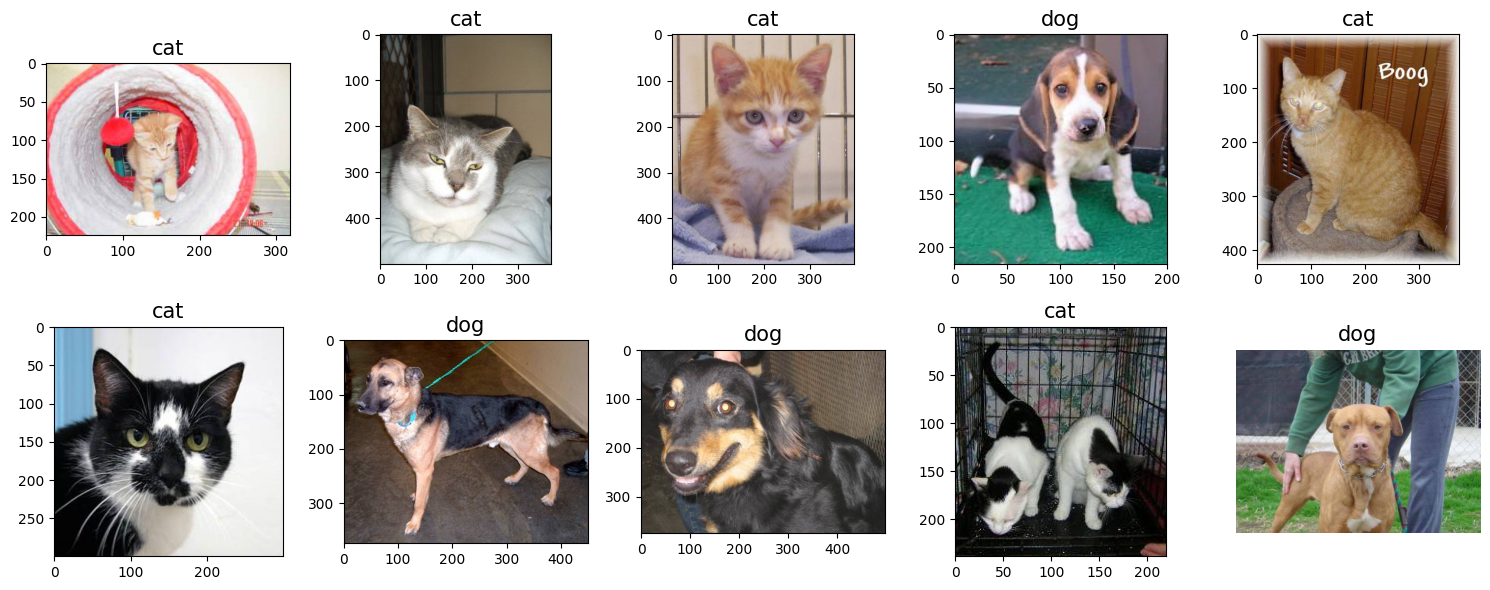

In [6]:
random_idx = np.random.randint(1, 25000, size=10)

fig = plt.figure(figsize=(15, 6))
i = 1
for idx in random_idx:
    ax = fig.add_subplot(2, 5, i)
    img = Image.open(train_list[idx])
    img_path = train_list[idx]
    label = img_path.split('\\')[-1].split('.')[0]
    plt.imshow(img)
    plt.title(label, size=15)
    i += 1

plt.tight_layout()
plt.axis('off')
plt.show()

In [7]:
h_list = []
w_list = []
band_set = set()

for train_img in train_list:
    img = Image.open(train_img)
    w, h = img.size
    h_list.append(h)
    w_list.append(w)
    band_set.add(img.getbands())

w_med, h_med = np.percentile(w_list, q=80), np.percentile(h_list, q=80)
print(w_med, h_med)
print('channels: ', band_set)

500.0 456.0
channels:  {('R', 'G', 'B')}


<h3>Агностика

In [8]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

torch.manual_seed(SEED)
if device == 'cuda':
    torch.cuda.manual_seed_all(SEED)

print('device: ', device)

device:  cuda


In [9]:
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomVerticalFlip(p=0.5),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.Resize([227, 227]),
        transforms.ToTensor()
    ]),
    'test': transforms.Compose([
        transforms.Resize([227, 227]),
        transforms.ToTensor()
    ])
}

In [10]:
class CatDogs(Dataset):
    def __init__(self, file_list, transforms=None):
        self.file_list = file_list
        self.transforms = transforms

    def __len__(self):
        return len(self.file_list)
    
    def __getitem__(self, idx):
        img_path = self.file_list[idx]
        img = Image.open(img_path)
        if self.transforms is not None:
            img = self.transforms(img)
        label = img_path.split('\\')[-1].split('.')[0]
        if label == 'dog':
            label = 1
        else:
            label = 0
        
        return img, label


In [11]:
train_data, valid_data = train_test_split(train_list, test_size=.1)

train_dataset = CatDogs(train_data, transforms=data_transforms['train'])
valid_dataset = CatDogs(valid_data, transforms=data_transforms['test'])
test_dataset = CatDogs(test_list, transforms=data_transforms['test'])

num_workers = multiprocessing.cpu_count()
print(f'Number of workers: {num_workers}')
num_workers = 0
# 0 так как без 0 ничего не работает

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                        num_workers=num_workers, pin_memory=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=num_workers, pin_memory=True)

Number of workers: 12


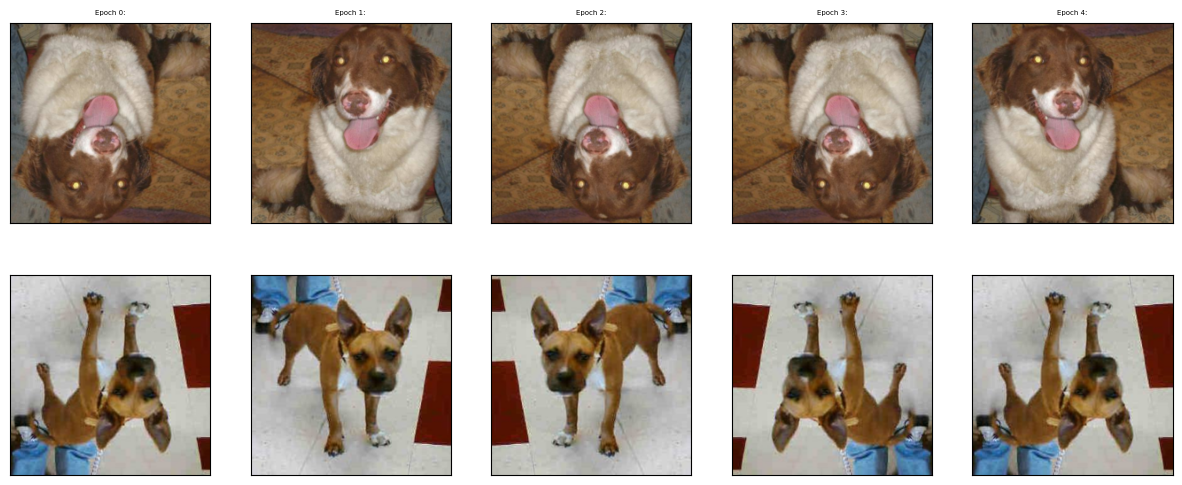

In [12]:
template_dl = DataLoader(train_dataset, batch_size=2)
fig = plt.figure(figsize=(15, 6))
num_epoch = 5
for j in range(num_epoch):
    data, loader = next(iter(template_dl))
    img = data[0]
    ax = fig.add_subplot(2, 5, j + 1)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'Epoch {j}:', size=5)
    ax.imshow(img.permute(1, 2, 0))
    
    img = data[1]
    ax = fig.add_subplot(2, 5, j + 6)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.imshow(img.permute(1, 2, 0))
    # permute для перемещения слоёв BGR2RGB
plt.show()

<h1>Архитектура AlexNet

In [13]:
Row = make_dataclass('Row', [
    'Layer', 
    'Type', 
    ('Out_Channels', int), 
    'Kernel_Size', 
    ('Stride', int), 
    ('Padding', int), 
    ('Activation', str)
])

df = pd.DataFrame([
    Row('In', 'Input', 3, None, None, None, None),
    Row('C1', 'Convolution', 64, '11x11', 4, 2, 'ReLU'),
    Row('P2', 'Max Pooling', 64, '3x3', 2, 0, None),
    Row('C3', 'Convolution', 192, '5x5', 1, 2, 'ReLU'),
    Row('P4', 'Max Pooling', 192, '3x3', 2, 0, None),
    Row('C5', 'Convolution', 384, '3x3', 1, 1, 'ReLU'),
    Row('C6', 'Convolution', 256, '3x3', 1, 1, 'ReLU'),
    Row('C7', 'Convolution', 256, '3x3', 1, 1, 'ReLU'),
    Row('P8', 'Max Pooling', 256, '3x3', 2, 0, None),
    Row('P9', 'Avg Pooling', 256, 'None', None, None, None),
    Row('F10', 'Flatten', 9216, None, None, None, None),
    Row('F11', 'Fully Connected', 4096, None, None, None, 'ReLU'),
    Row('F12', 'Fully Connected', 4096, None, None, None, 'ReLU'),
    Row('Out', 'Fully Connected', 'Num Classes', None, None, None, 'Softmax')
])

# Отображение таблицы
display(df)

,Layer,Type,Out_Channels,Kernel_Size,Stride,Padding,Activation
0,In,Input,3,NaN,NaN,NaN,NaN
1,C1,Convolution,64,11x11,4.0,2.0,ReLU
2,P2,Max Pooling,64,3x3,2.0,0.0,NaN
3,C3,Convolution,192,5x5,1.0,2.0,ReLU
4,P4,Max Pooling,192,3x3,2.0,0.0,NaN
5,C5,Convolution,384,3x3,1.0,1.0,ReLU
6,C6,Convolution,256,3x3,1.0,1.0,ReLU
7,C7,Convolution,256,3x3,1.0,1.0,ReLU
8,P8,Max Pooling,256,3x3,2.0,0.0,NaN
9,P9,Avg Pooling,256,None,NaN,NaN,NaN


In [14]:
class AlexNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=64, kernel_size=11,
                      stride=4, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(in_channels=64, out_channels=192, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(in_channels=192, out_channels=384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=384, out_channels=256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2)
        )
        self.avgpool = nn.AdaptiveAvgPool2d((6, 6))
        self.classifier = nn.Sequential(
            nn.Dropout(.5),
            nn.Linear(in_features=256 * 6 * 6, out_features=4096),
            nn.ReLU(inplace=True),
            nn.Dropout(.5),
            nn.Linear(in_features=4096, out_features=4096),
            nn.ReLU(inplace=True),
            nn.Linear(4096, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        logits = self.classifier(x)
        probas = F.softmax(logits, dim=-1)
        return logits

In [15]:
model = AlexNet(num_classes=NUM_CLASSES)
# device = torch.device("cuda:0")
model.to(device)

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

In [16]:
print(sum(p.numel() for p in model.parameters()))

57012034


In [17]:
criterion = F.cross_entropy
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

F.cross_entropy у нас, а не nn так как у нас именно softmax в конце!

А в nn у нас там он уже заложен -> два раза по вероятностям смотрим...

In [ ]:
def train(model, num_epochs, train_loader, valid_loader):
    model.to(device)
    loss_hist_train = [0] * num_epochs
    accuracy_hist_train = [0] * num_epochs
    loss_hist_valid = [0] * num_epochs
    accuracy_hist_valid = [0] * num_epochs
    for epoch in range(num_epochs):
        model = model.train()
        for idx, (data, target) in enumerate(train_loader):
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            _, pred = torch.max(output, dim=1)
            loss.backward()
            optimizer.step()
            loss_hist_train[epoch] += loss.item() * target.size(0)
            is_correct = ((pred >= .5).float() == target).float()
            # is_correct = (pred == target).float()
            accuracy_hist_train[epoch] += is_correct.sum()

            if not idx % 40:
                print("Epoch %03d/%03d | Batch %03d/%03d | Loss %.4f" % (epoch + 1,
                             num_epochs, idx, len(train_loader), loss))
                
        loss_hist_train[epoch] /= len(train_loader.dataset)
        accuracy_hist_train[epoch] /= len(train_loader.dataset)

        model = model.eval()
        with torch.inference_mode():
            for idx, (data, target) in enumerate(valid_loader):
                data, target = data.to(device), target.to(device)
                output = model(data)
                loss = criterion(output, target)
                _, pred = torch.max(output, 1)
                loss_hist_valid[epoch] += loss.item() * target.size(0)
                is_correct = ((pred >= .5).float() == target).float()
                # is_correct = (pred == target).float()
                accuracy_hist_valid[epoch] += is_correct.sum()
            loss_hist_valid[epoch] /= len(valid_loader.dataset)
            accuracy_hist_valid[epoch] /= len(valid_loader.dataset)

        print(f'Epoch: {epoch + 1} | accuracy: '\
              f'{accuracy_hist_train[epoch]:.4f} val_accuracy: '\
              f'{accuracy_hist_valid[epoch]:.4f}')
    return loss_hist_train, loss_hist_valid, accuracy_hist_train, accuracy_hist_valid

In [19]:
train(model, EPOCHS, train_loader, valid_loader)

C:\Users\nuyki\AppData\Local\Temp\ipykernel_23900\4051792047.py:23: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  print("Epoch %03d/%03d | Batch %03d/%03d | Loss %.4f" % (epoch + 1,


Epoch 001/060 | Batch 000/088 | Loss 0.6933
Epoch 001/060 | Batch 040/088 | Loss 0.7411
Epoch 001/060 | Batch 080/088 | Loss 0.6780
Epoch: 1 | accuracy: 0.5670 val_accuracy:0.6148
Epoch 002/060 | Batch 000/088 | Loss 0.6474
Epoch 002/060 | Batch 040/088 | Loss 0.6208
Epoch 002/060 | Batch 080/088 | Loss 0.6360
Epoch: 2 | accuracy: 0.6321 val_accuracy:0.6396
Epoch 003/060 | Batch 000/088 | Loss 0.6092
Epoch 003/060 | Batch 040/088 | Loss 0.6553
Epoch 003/060 | Batch 080/088 | Loss 0.6064
Epoch: 3 | accuracy: 0.6537 val_accuracy:0.6380
Epoch 004/060 | Batch 000/088 | Loss 0.6220
Epoch 004/060 | Batch 040/088 | Loss 0.6081
Epoch 004/060 | Batch 080/088 | Loss 0.5888
Epoch: 4 | accuracy: 0.6695 val_accuracy:0.7228
Epoch 005/060 | Batch 000/088 | Loss 0.5744
Epoch 005/060 | Batch 040/088 | Loss 0.5285
Epoch 005/060 | Batch 080/088 | Loss 0.4918
Epoch: 5 | accuracy: 0.7244 val_accuracy:0.7216
Epoch 006/060 | Batch 000/088 | Loss 0.5184
Epoch 006/060 | Batch 040/088 | Loss 0.4739
Epoch 006/06

KeyboardInterrupt: 

In [20]:
torch.save(model.state_dict(), 'D:/MIREA/DPO/Learning/Practic2_6/AlexNet.pth')